<Figure size 1000x400 with 0 Axes>

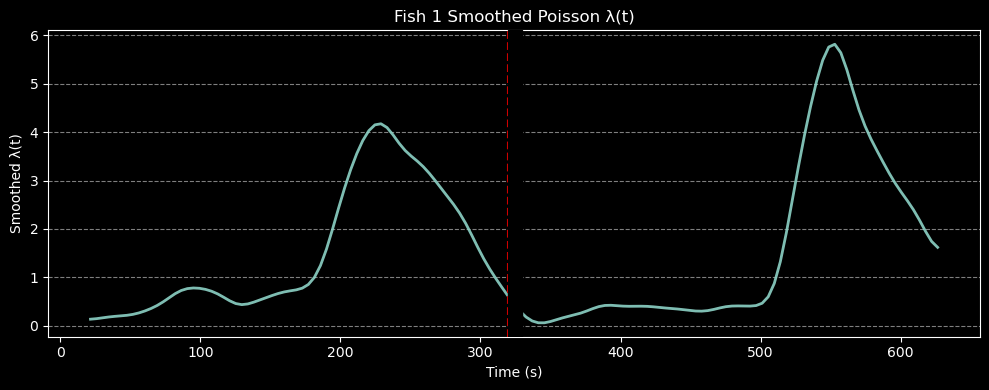

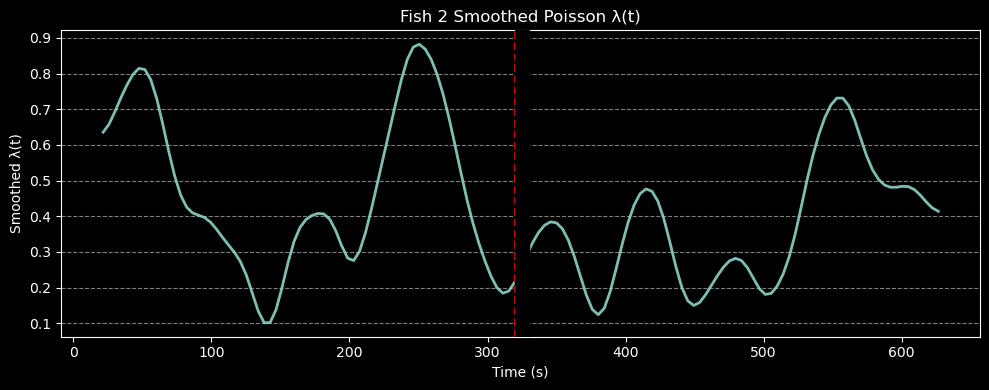

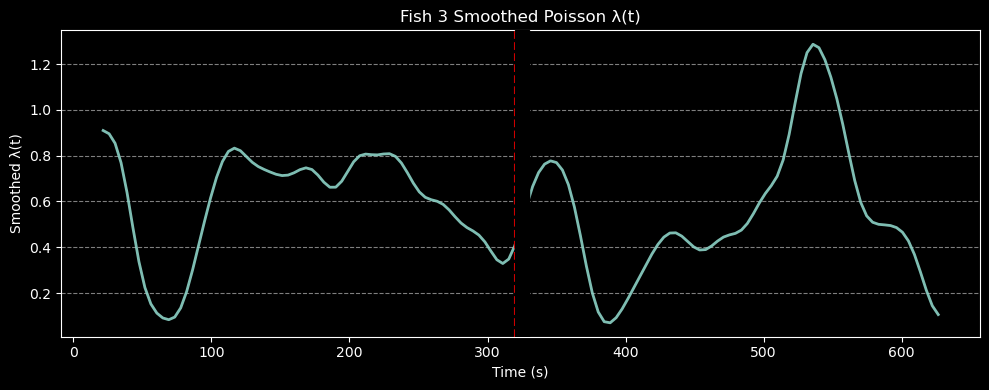

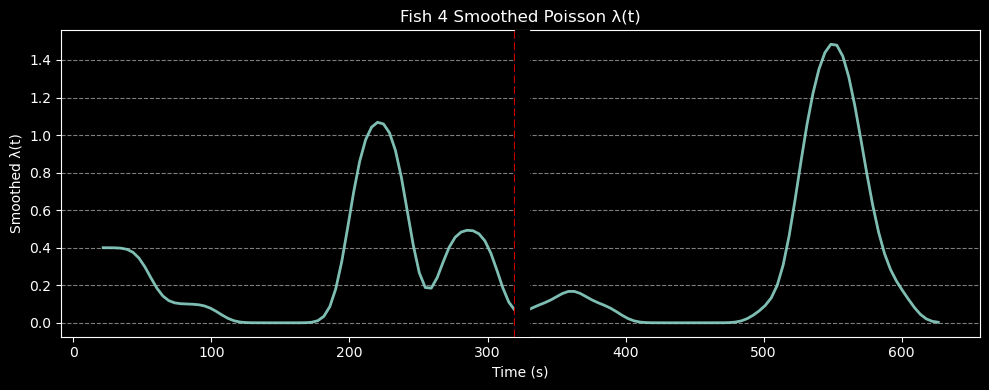

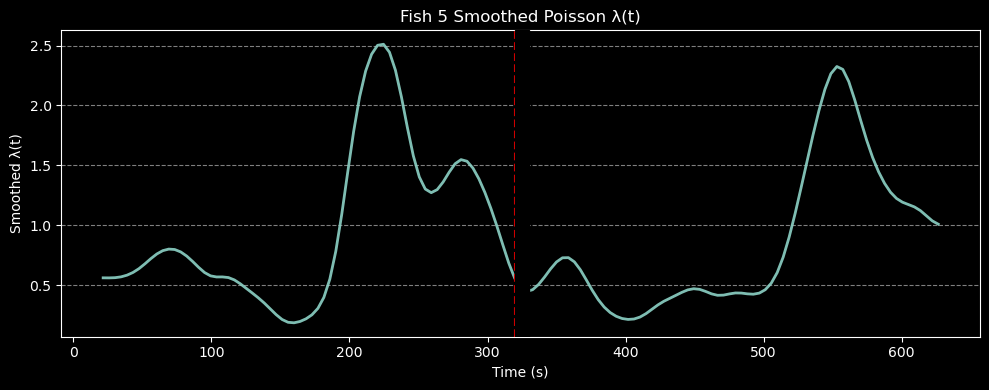

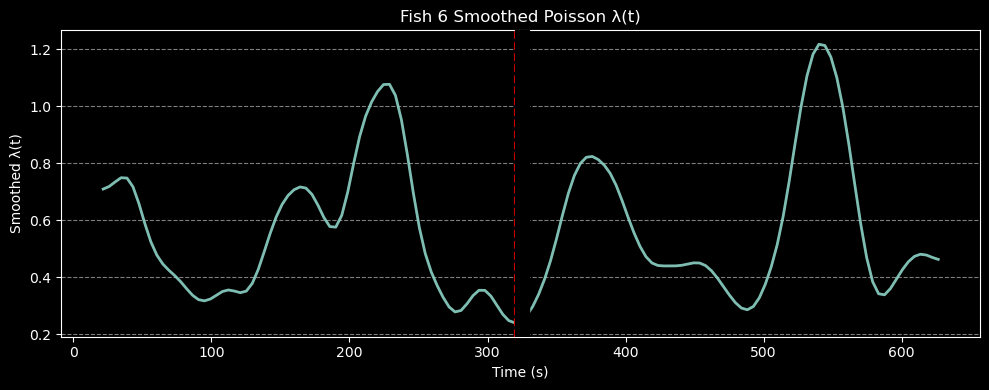

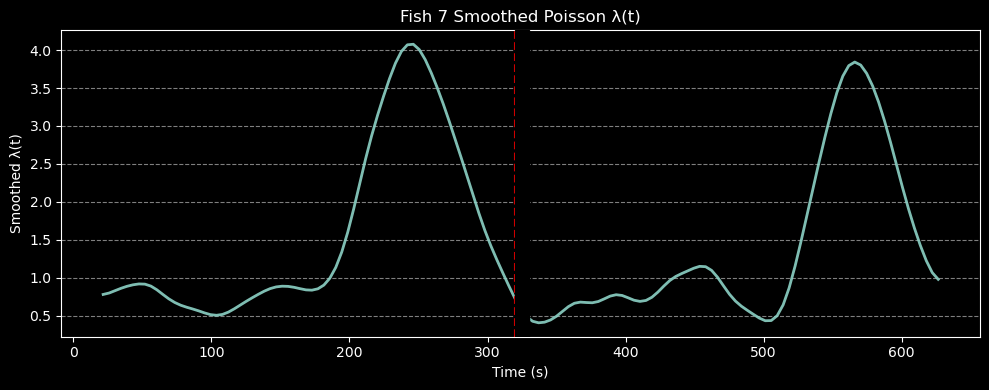

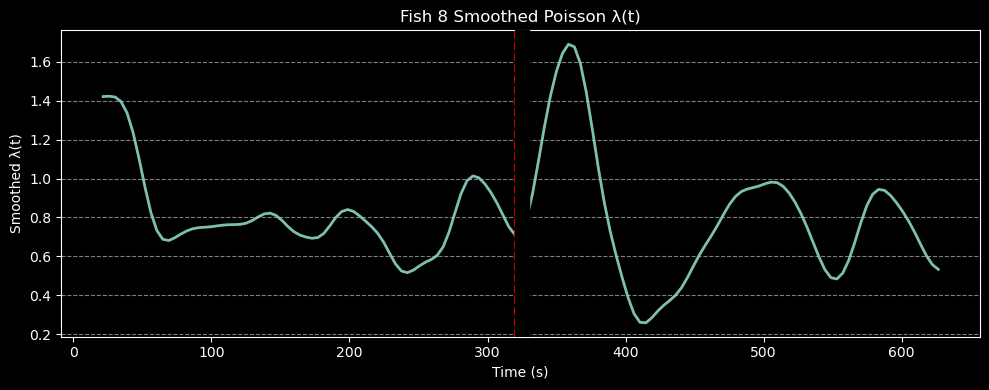

/Users/haotianli/Code/EngertLab/Methods.py:362: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


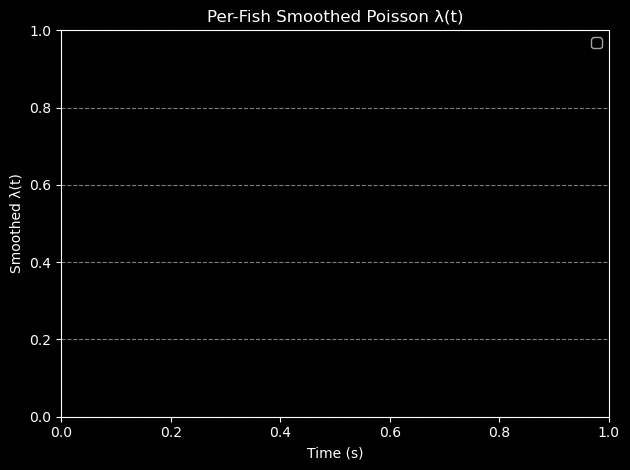

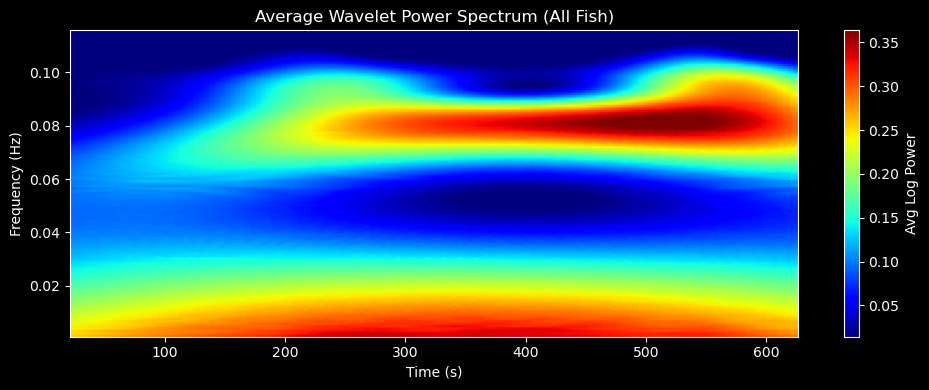

<Figure size 1000x400 with 0 Axes>

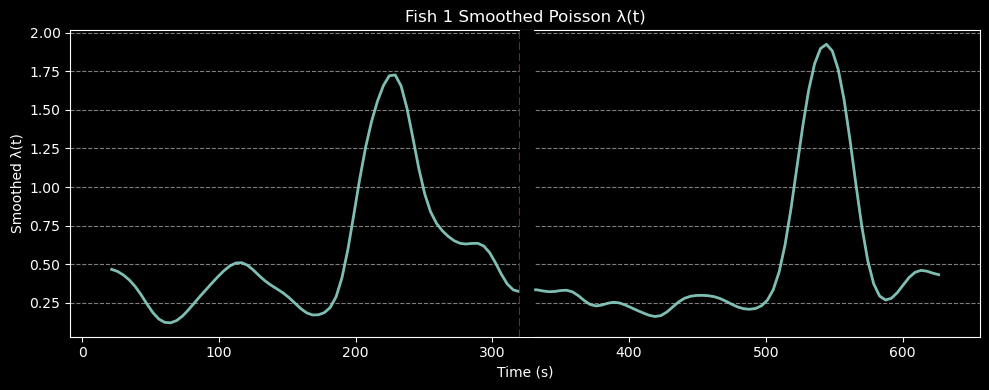

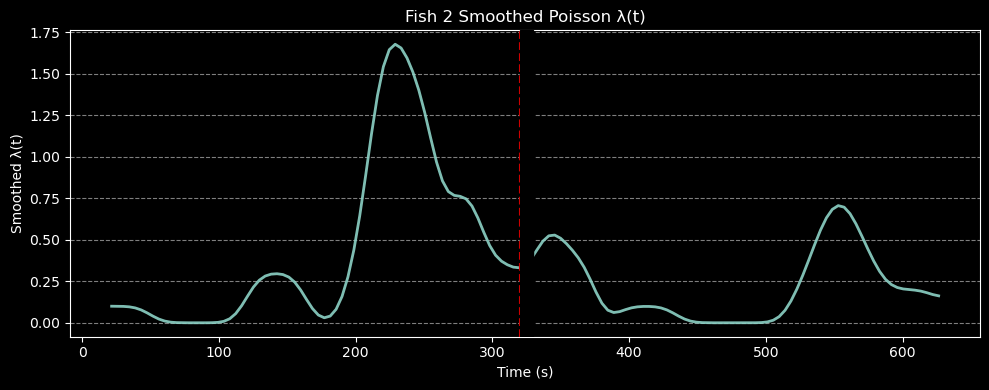

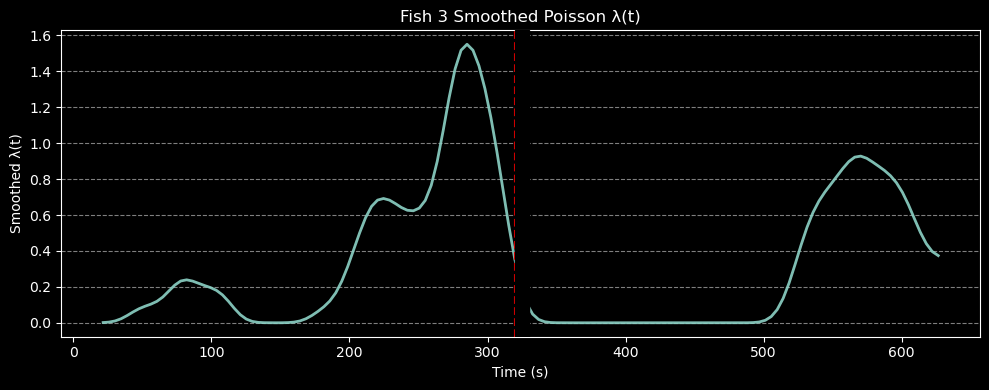

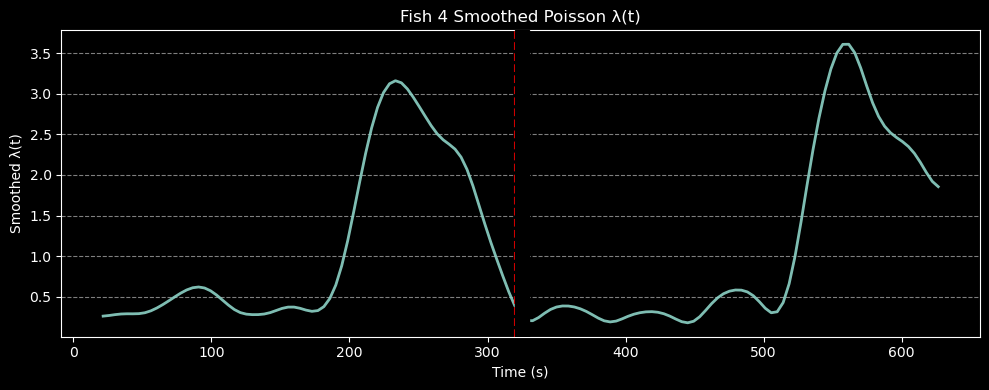

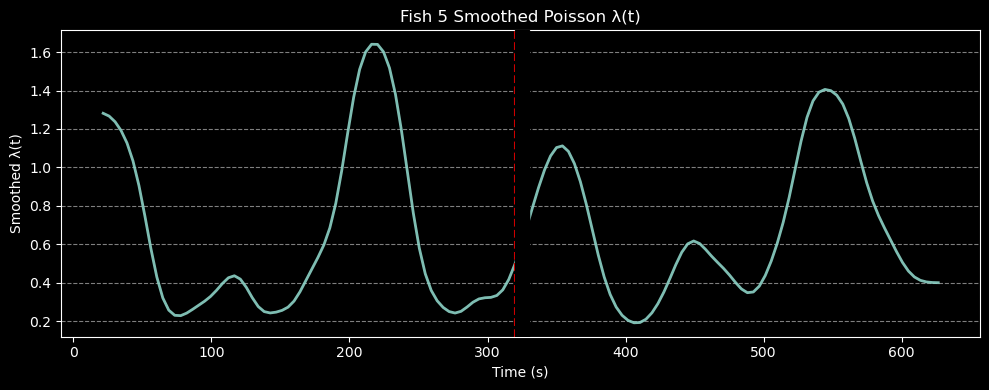

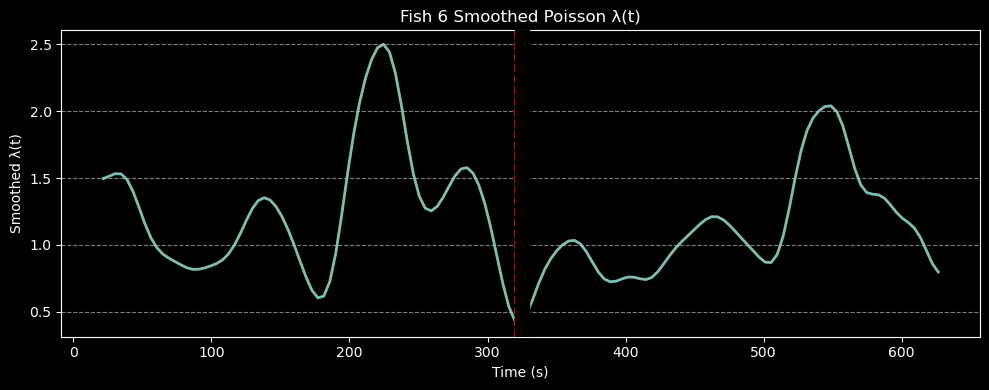

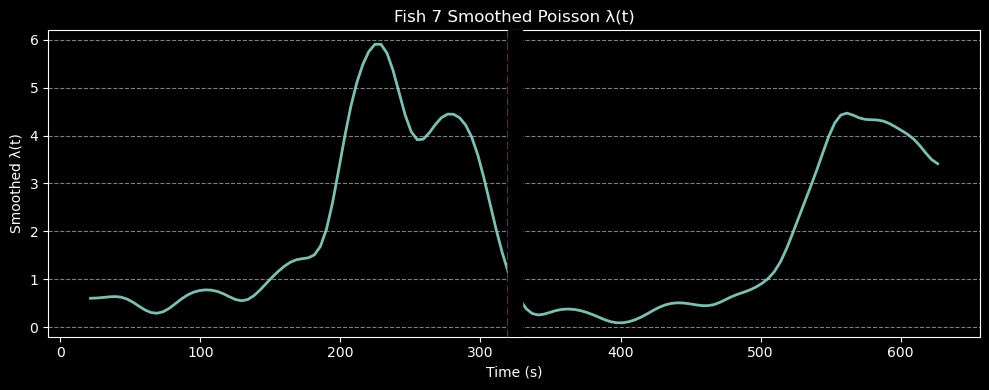

/Users/haotianli/Code/EngertLab/Methods.py:362: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


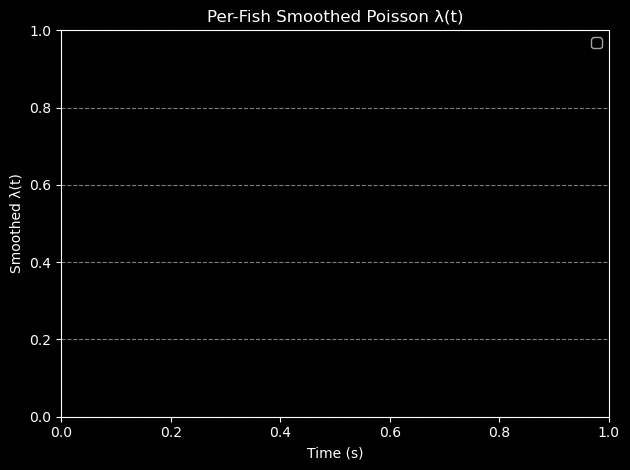

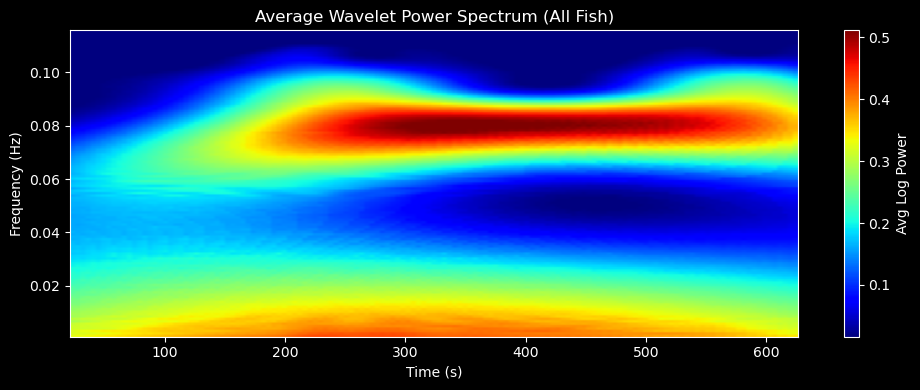

(8, 38874) (7, 38878)


In [1]:
### Contrast Group
import numpy as np
import matplotlib.pyplot as plt
from Methods import stimuli, file_process
##############################
contrast_rig1_0727_path = "/Users/haotianli/Code/EngertLab/Data/20250727_rig1/stimulus_int_and_damp"
contrast_rig1_0727_stimulus_data_paths, contrast_rig1_0727_HT_data_paths = file_process.extract_from_stimuli(contrast_rig1_0727_path)
stimuli_rig1_0727_contrast = stimuli(contrast_rig1_0727_stimulus_data_paths, contrast_rig1_0727_HT_data_paths)

stimuli_rig1_0727_contrast_struggle, time_axes, avg_power_rig1_0727, stimulus_frame_count = stimuli_rig1_0727_contrast.struggle_detection(threshold=90, mode="fish_two_trials_concatenate")


##############################
contrast_rig2_0727_path = "/Users/haotianli/Code/EngertLab/Data/20250727_rig2/stimulus_int_and_damp (1)"
contrast_rig2_0727_stimulus_data_paths, contrast_rig2_0727_HT_data_paths = file_process.extract_from_stimuli(contrast_rig2_0727_path)
stimuli_rig2_0727_contrast = stimuli(contrast_rig2_0727_stimulus_data_paths, contrast_rig2_0727_HT_data_paths)

stimuli_rig2_0727_contrast_struggle, _, avg_power_rig2_0727, stimulus_frame_count = stimuli_rig2_0727_contrast.struggle_detection(threshold=90, mode="fish_two_trials_concatenate")

print(stimuli_rig1_0727_contrast_struggle.shape, stimuli_rig2_0727_contrast_struggle.shape)


# Similarity Matrix inside or outside the fish

(12, 38878)


/Users/haotianli/miniconda3/envs/Universal/lib/python3.10/site-packages/seaborn/matrix.py:1124: UserWarning: ``square=True`` ignored in clustermap
  warnings.warn(msg)
/Users/haotianli/miniconda3/envs/Universal/lib/python3.10/site-packages/seaborn/matrix.py:1124: UserWarning: ``square=True`` ignored in clustermap
  warnings.warn(msg)


<Figure size 800x600 with 0 Axes>

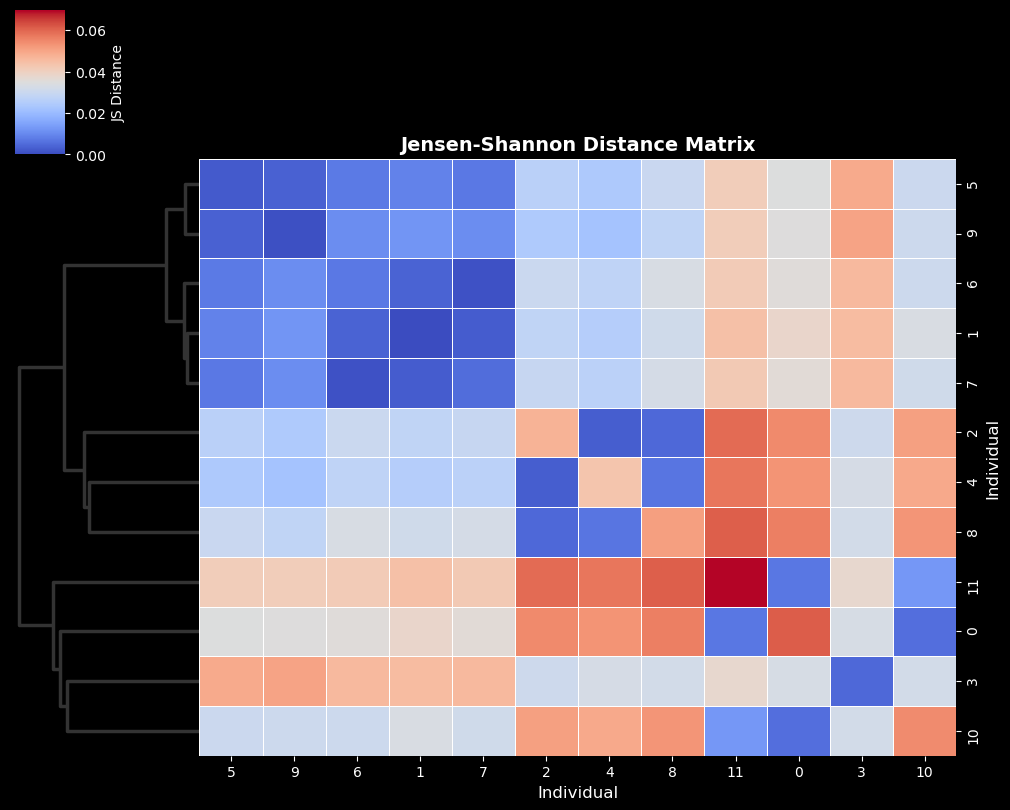

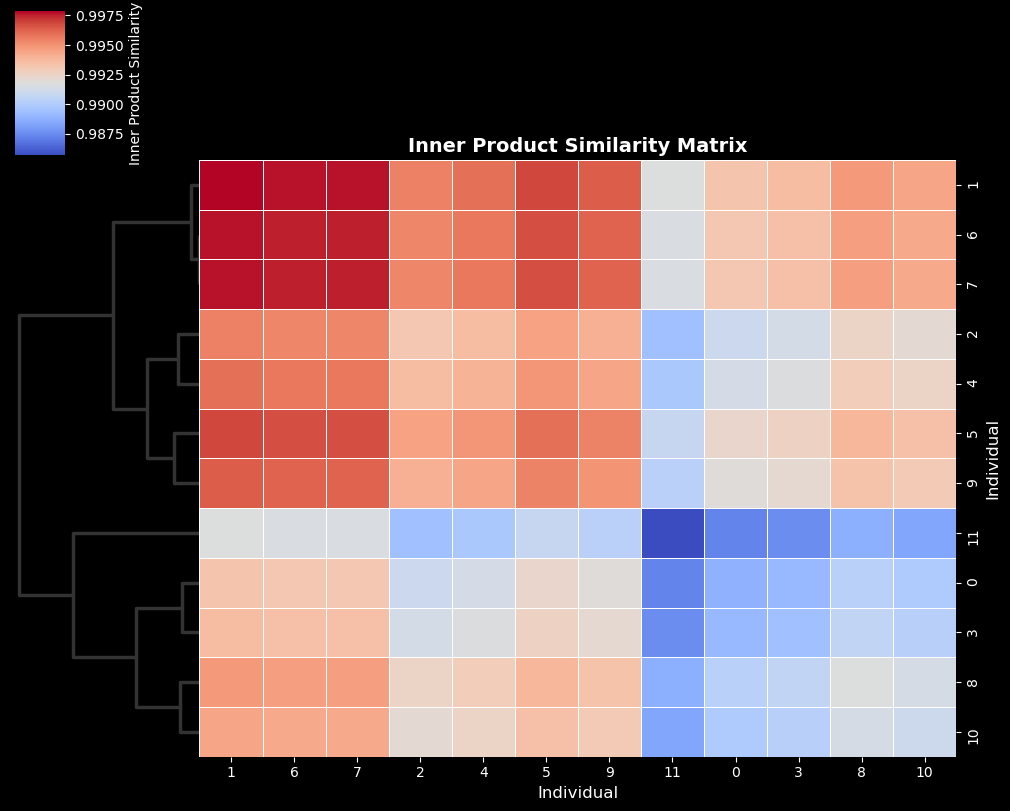

array([[0.98876599, 0.99329578, 0.9909655 , 0.98908654, 0.99134932,
        0.99232698, 0.99314368, 0.99314342, 0.99024958, 0.99186736,
        0.98991611, 0.98724557],
       [0.99329578, 0.99784173, 0.99550419, 0.99360118, 0.99588954,
        0.99686642, 0.99768773, 0.99768773, 0.9947854 , 0.99640444,
        0.99442594, 0.99172988],
       [0.9909655 , 0.99550419, 0.9931699 , 0.99128335, 0.99356441,
        0.99453149, 0.99535015, 0.99535029, 0.99246585, 0.99407111,
        0.99209346, 0.98940217],
       [0.98908654, 0.99360118, 0.99128335, 0.98940687, 0.99166513,
        0.9926291 , 0.99344782, 0.99344778, 0.99056761, 0.99216854,
        0.99020856, 0.9875276 ],
       [0.99134932, 0.99588954, 0.99356441, 0.99166513, 0.99393925,
        0.99491639, 0.99573539, 0.99573554, 0.99284849, 0.99445584,
        0.99247759, 0.9897852 ],
       [0.99232698, 0.99686642, 0.99453149, 0.9926291 , 0.99491639,
        0.99589298, 0.99671284, 0.99671281, 0.99381384, 0.99543193,
        0.99345573,

In [2]:
from Similarity_Metrics import Similarity
# JS distance matrix
## step1. get the proper struggle matrix and concatenate them
### Here we use [rig1] 0 3 4 6 7 and [rig2] 0 1 2 3 4 5 6
if stimuli_rig1_0727_contrast_struggle.shape[1] != stimuli_rig2_0727_contrast_struggle.shape[1]:
    stimuli_rig1_0727_contrast_struggle = np.pad(stimuli_rig1_0727_contrast_struggle, pad_width=((0, 0), (2, 2)), mode='constant', constant_values=0)

struggle_vector = np.stack([
    stimuli_rig1_0727_contrast_struggle[0],
    stimuli_rig1_0727_contrast_struggle[3],
    stimuli_rig1_0727_contrast_struggle[4],
    stimuli_rig1_0727_contrast_struggle[6],
    stimuli_rig1_0727_contrast_struggle[7],
    stimuli_rig2_0727_contrast_struggle[0],
    stimuli_rig2_0727_contrast_struggle[1],
    stimuli_rig2_0727_contrast_struggle[2],
    stimuli_rig2_0727_contrast_struggle[3],
    stimuli_rig2_0727_contrast_struggle[4],
    stimuli_rig2_0727_contrast_struggle[5],
    stimuli_rig2_0727_contrast_struggle[6]
], axis=0)

print(struggle_vector.shape)

similarity = Similarity(struggle_vector)
similarity.JS_heatmap()
similarity.inner_product_heatmap()